In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df_tda = pd.read_csv("Caco2_Papp_20449_single_fragment_dataset.csv")

print("Rows:", df_tda.shape[0])
print("Columns:", df_tda.shape[1])

Rows: 20449
Columns: 15


In [4]:
print(df_tda.columns.tolist())

['canonical_smiles', 'n_measurements', 'n_assays', 'min_papp', 'max_papp', 'median_papp', 'mean_papp', 'log10_range', 'log10_median_papp', 'mean_median_ratio', 'mol', 'rdkit_canonical_smiles', 'n_fragments', 'parent_mol', 'parent_smiles']


In [5]:
print(df_tda["log10_median_papp"].describe())

count    20449.000000
mean         0.852952
std          0.820542
min         -4.000000
25%          0.380211
50%          0.982271
75%          1.361728
max          4.444661
Name: log10_median_papp, dtype: float64


In [7]:
target = df_tda["log10_median_papp"]

# TDA-1 — Target overview

In [9]:
target = df_tda["log10_median_papp"]

print("=== Target: log10(median Papp) ===")
print(target.describe())

print("\n=== Additional statistics ===")
print("Skewness:", target.skew())
print("Kurtosis:", target.kurtosis())
print("Missing values:", target.isna().sum())
print("Unique target values:", target.nunique())

=== Target: log10(median Papp) ===
count    20449.000000
mean         0.852952
std          0.820542
min         -4.000000
25%          0.380211
50%          0.982271
75%          1.361728
max          4.444661
Name: log10_median_papp, dtype: float64

=== Additional statistics ===
Skewness: -0.4687295703347788
Kurtosis: 1.4974152665471814
Missing values: 0
Unique target values: 3550


The target has no missing values, and the transformation gives us a well-defined continuous target across the 20,449 molecules.
The distribution shows moderate negative skewness (−0.469), with a relatively extended lower tail and some high-valued observations. 

We should not remove those extremes at this stage; they are part of the chemical/experimental distribution that our later chemical-space analysis needs to account for.

# TDA-2 -visualize the target distribution.

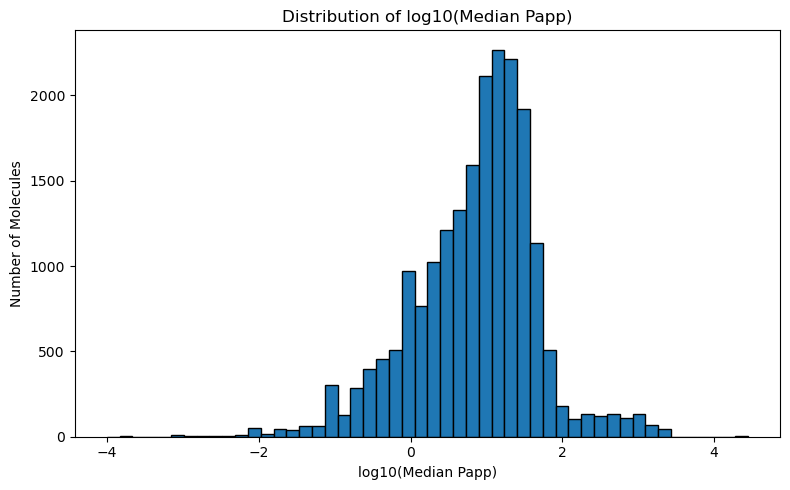

In [10]:
plt.figure(figsize=(8, 5))

plt.hist(
    target,
    bins=50,
    edgecolor="black"
)

plt.xlabel("log10(Median Papp)")
plt.ylabel("Number of Molecules")
plt.title("Distribution of log10(Median Papp)")
plt.tight_layout()
plt.show()

- The target is concentrated mainly around 0–2 log10(Median Papp).
- The highest density is around ~0.8–1.4.
- There is a longer lower tail extending toward −4, consistent with the negative skewness we calculated.
- There is also a smaller upper tail extending toward ~4.4.
- The distribution is therefore not perfectly symmetric/normal.

# TDA-3 — Identify target extremes

In [12]:
print("Lowest 10 log10(Median Papp) values:")
print(
    df_tda[["canonical_smiles", "log10_median_papp"]]
    .sort_values("log10_median_papp")
    .head(10)
)

Lowest 10 log10(Median Papp) values:
                                        canonical_smiles  log10_median_papp
3066   CC1=C(C(=O)O)N2C(=O)[C@@H](NC(=O)[C@H](N)c3ccc...          -4.000000
7182   CNC(=O)c1ccc(Oc2ccc(S(=O)(=O)[C@]3(C(=O)NO)CCC...          -3.795880
18185  O=C(Nc1c2c(cc3c1CCC3)CCC2)O[C@H](Cc1ncccn1)C(=O)O          -3.698970
9481   COc1ccc(C(=O)Oc2ccc(S(=O)(=O)C3(C(=O)NO)CCC4(C...          -3.698970
1657   CC(C)(O)c1coc(S(=O)(=O)NC(=O)Nc2c3c(cc4c2CCC4)...          -3.522879
20174  S=c1cc(CC2CCCCO2)[nH]c2nc(Nc3c4c(cc5c3CCC5)CCC...          -3.397940
7181   CNC(=O)c1ccc(Oc2ccc(S(=O)(=O)[C@@]3(C(=O)NO)CC...          -3.229148
15268  Cn1cccc1C(=O)N1CCN(C(=O)Nc2ccc(N3CCC(C(=O)N4CC...          -3.154902
18006  O=C(NO)C1(S(=O)(=O)c2ccc(Oc3ccc(OC(F)(F)F)cc3)...          -3.154902
16626  NCCCC[C@@H]1NC(=O)[C@H](Cc2ccc(O)cc2)NC(=O)[C@...          -3.096910


In [13]:
print("\nHighest 10 log10(Median Papp) values:")
print(
    df_tda[["canonical_smiles", "log10_median_papp"]]
    .sort_values("log10_median_papp", ascending=False)
    .head(10)
)


Highest 10 log10(Median Papp) values:
                                        canonical_smiles  log10_median_papp
18311  O=C(Nc1ccc([N+](=O)[O-])cc1)N[C@H](Cc1cccnc1)C...           4.444661
15926  N#Cc1ccc(C[C@H](NC(=O)Nc2ccc(F)cc2)C(=O)NCC2(c...           4.416226
15927  N#Cc1ccc(C[C@H](NC(=O)Nc2ccc([N+](=O)[O-])cc2)...           4.180152
4705   CCOC(=O)c1c(-c2cccc(-c3ccccc3)c2)[nH]c2cc(OC)c...           3.462398
3622                        CCCCCCc1ccc(C(=O)CCN(C)C)cc1           3.366049
3605      CCCCCCSc1ccc(C(=O)CCN2CCN(C(C)=O)CC2)c(Cl)c1Cl           3.361728
3544                 CCCCCCOc1ccc(C(=O)CCN2CCN(C)CC2)cc1           3.361728
13668     Cc1cccc(-n2cnc3cc(C(=O)N4CCCC(C)(C)C4)ccc32)c1           3.355068
18316  O=C(Nc1ccc([N+](=O)[O-])cc1Cl)c1cc(Cl)ccc1NS(=...           3.352183
14577  Cc1noc(C)c1-c1ccc2nc(-c3cnn(CCO)c3)nc(N3CCOCC3...           3.343212


# TDA-4 — Measurement support for target extremes

In [14]:
extreme_df = (
    df_tda[
        ["canonical_smiles", "log10_median_papp",
         "n_measurements", "n_assays",
         "min_papp", "max_papp", "median_papp"]
    ]
    .sort_values("log10_median_papp")
)

print("Lowest 10:")
display(extreme_df.head(10))

print("\nHighest 10:")
display(extreme_df.tail(10))

Lowest 10:


,canonical_smiles,log10_median_papp,n_measurements,n_assays,min_papp,max_papp,median_papp
3066,CC1=C(C(=O)O)N2C(=O)[C@@H](NC(=O)[C@H](N)c3ccc...,-4.000000,1,1,0.00010,0.00010,0.00010
7182,CNC(=O)c1ccc(Oc2ccc(S(=O)(=O)[C@]3(C(=O)NO)CCC...,-3.795880,1,1,0.00016,0.00016,0.00016
18185,O=C(Nc1c2c(cc3c1CCC3)CCC2)O[C@H](Cc1ncccn1)C(=O)O,-3.698970,1,1,0.00020,0.00020,0.00020
9481,COc1ccc(C(=O)Oc2ccc(S(=O)(=O)C3(C(=O)NO)CCC4(C...,-3.698970,1,1,0.00020,0.00020,0.00020
1657,CC(C)(O)c1coc(S(=O)(=O)NC(=O)Nc2c3c(cc4c2CCC4)...,-3.522879,1,1,0.00030,0.00030,0.00030
20174,S=c1cc(CC2CCCCO2)[nH]c2nc(Nc3c4c(cc5c3CCC5)CCC...,-3.397940,1,1,0.00040,0.00040,0.00040
7181,CNC(=O)c1ccc(Oc2ccc(S(=O)(=O)[C@@]3(C(=O)NO)CC...,-3.229148,1,1,0.00059,0.00059,0.00059
15268,Cn1cccc1C(=O)N1CCN(C(=O)Nc2ccc(N3CCC(C(=O)N4CC...,-3.154902,1,1,0.00070,0.00070,0.00070
18006,O=C(NO)C1(S(=O)(=O)c2ccc(Oc3ccc(OC(F)(F)F)cc3)...,-3.154902,1,1,0.00070,0.00070,0.00070
16626,NCCCC[C@@H]1NC(=O)[C@H](Cc2ccc(O)cc2)NC(=O)[C@...,-3.096910,1,1,0.00080,0.00080,0.00080



Highest 10:


,canonical_smiles,log10_median_papp,n_measurements,n_assays,min_papp,max_papp,median_papp
14577,Cc1noc(C)c1-c1ccc2nc(-c3cnn(CCO)c3)nc(N3CCOCC3...,3.343212,1,1,2204.0,2204.0,2204.00
18316,O=C(Nc1ccc([N+](=O)[O-])cc1Cl)c1cc(Cl)ccc1NS(=...,3.352183,1,1,2250.0,2250.0,2250.00
13668,Cc1cccc(-n2cnc3cc(C(=O)N4CCCC(C)(C)C4)ccc32)c1,3.355068,1,1,2265.0,2265.0,2265.00
3544,CCCCCCOc1ccc(C(=O)CCN2CCN(C)CC2)cc1,3.361728,1,1,2300.0,2300.0,2300.00
3605,CCCCCCSc1ccc(C(=O)CCN2CCN(C(C)=O)CC2)c(Cl)c1Cl,3.361728,1,1,2300.0,2300.0,2300.00
3622,CCCCCCc1ccc(C(=O)CCN(C)C)cc1,3.366049,1,1,2323.0,2323.0,2323.00
4705,CCOC(=O)c1c(-c2cccc(-c3ccccc3)c2)[nH]c2cc(OC)c...,3.462398,1,1,2900.0,2900.0,2900.00
15927,N#Cc1ccc(C[C@H](NC(=O)Nc2ccc([N+](=O)[O-])cc2)...,4.180152,2,2,4978.5,25303.3,15140.90
15926,N#Cc1ccc(C[C@H](NC(=O)Nc2ccc(F)cc2)C(=O)NCC2(c...,4.416226,2,2,14552.1,37598.1,26075.10
18311,O=C(Nc1ccc([N+](=O)[O-])cc1)N[C@H](Cc1cccnc1)C...,4.444661,2,2,11924.5,43754.4,27839.45


# TDA-5 — How much experimental support does the whole dataset have?

In [15]:
print(df_tda["n_measurements"].describe())

print("\nMeasurement count distribution:")
print(df_tda["n_measurements"].value_counts().sort_index())

count    20449.000000
mean         1.373221
std          2.378046
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max        115.000000
Name: n_measurements, dtype: float64

Measurement count distribution:
n_measurements
1      16035
2       3665
3        313
4        273
5         30
6         31
7         13
8         22
9          4
10         8
11         5
12         3
13         3
14         3
15         1
16         2
17         1
19         1
20         1
22         2
24         1
25         3
26         2
28         1
29         3
30         2
34         2
36         1
37         1
39         1
40         1
41         1
45         1
47         2
58         1
60         1
65         1
71         1
75         1
83         1
87         1
88         1
109        1
110        1
115        1
Name: count, dtype: int64


# Target variability by number of measurements

In [16]:
# Target variability by number of measurements

df_tda["log10_range"].groupby(
    df_tda["n_measurements"]
).describe()

,count,mean,std,min,25%,50%,75%,max
n_measurements,,,,,,,,
1,16035.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2,3665.0,0.501413,0.547850,0.000000,0.085011,0.301030,0.782516,4.623249
3,313.0,0.831377,0.648304,0.000000,0.301030,0.712650,1.285474,3.499398
4,273.0,0.778299,0.630320,0.000000,0.293968,0.588983,1.168592,3.111431
5,30.0,0.990898,0.496761,0.206244,0.594456,0.979926,1.213186,2.123125
6,31.0,0.992336,0.586725,0.085011,0.503772,1.041393,1.377767,2.138922
7,13.0,1.382541,0.856709,0.353814,0.725299,1.492916,1.647817,3.514149
8,22.0,1.258346,0.831752,0.388032,0.817352,1.097207,1.336862,4.176091
9,4.0,1.184913,0.147182,0.990689,1.136191,1.201088,1.249810,1.346787


In [18]:
import seaborn as sns

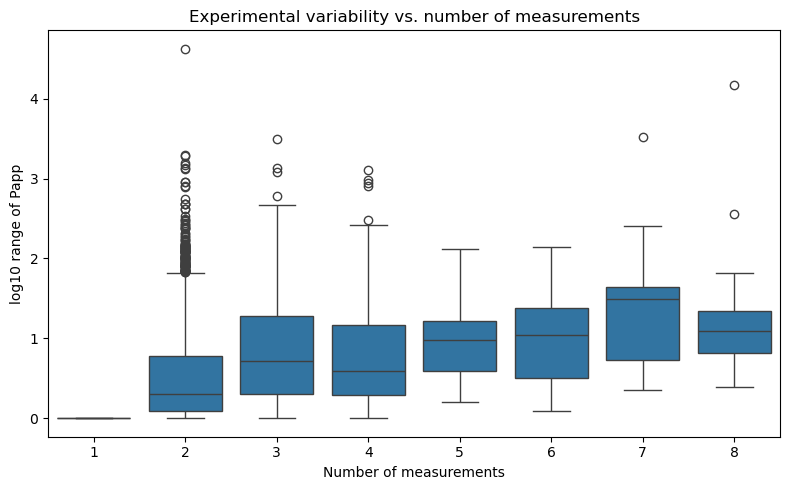

In [19]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_tda[df_tda["n_measurements"] <= 8],
    x="n_measurements",
    y="log10_range"
)

plt.xlabel("Number of measurements")
plt.ylabel("log10 range of Papp")
plt.title("Experimental variability vs. number of measurements")
plt.tight_layout()
plt.show()

# the Spearman correlation between n_measurements and log10_range.

In [20]:
tda_corr = df_tda[["n_measurements", "log10_range"]].corr(
    method="spearman"
)

print(tda_corr)

                n_measurements  log10_range
n_measurements        1.000000     0.946463
log10_range           0.946463     1.000000


# Does molecular size, polarity, lipophilicity, etc. explain the variation in Papp?

In [22]:
print(df_tda.columns.tolist())

['canonical_smiles', 'n_measurements', 'n_assays', 'min_papp', 'max_papp', 'median_papp', 'mean_papp', 'log10_range', 'log10_median_papp', 'mean_median_ratio', 'mol', 'rdkit_canonical_smiles', 'n_fragments', 'parent_mol', 'parent_smiles']


In [28]:
print(type(df_tda["mol"].iloc[0]))
print(df_tda["mol"].iloc[0])

<class 'str'>


In [30]:
from rdkit import Chem

df_tda["mol_rdkit"] = df_tda["canonical_smiles"].apply(Chem.MolFromSmiles)

print(type(df_tda["mol_rdkit"].iloc[0]))
print("Invalid molecules:", df_tda["mol_rdkit"].isna().sum())

<class 'rdkit.Chem.rdchem.Mol'>
Invalid molecules: 0


In [31]:
from rdkit.Chem import Descriptors, Lipinski

df_tda["MW"] = df_tda["mol_rdkit"].apply(Descriptors.MolWt)
df_tda["LogP"] = df_tda["mol_rdkit"].apply(Descriptors.MolLogP)
df_tda["HBD"] = df_tda["mol_rdkit"].apply(Lipinski.NumHDonors)
df_tda["HBA"] = df_tda["mol_rdkit"].apply(Lipinski.NumHAcceptors)
df_tda["TPSA"] = df_tda["mol_rdkit"].apply(Descriptors.TPSA)
df_tda["RotB"] = df_tda["mol_rdkit"].apply(Lipinski.NumRotatableBonds)
df_tda["RingCount"] = df_tda["mol_rdkit"].apply(Lipinski.RingCount)

print("Descriptors calculated successfully.")

print(df_tda[
    ["MW", "LogP", "HBD", "HBA", "TPSA", "RotB", "RingCount"]
].describe())

Descriptors calculated successfully.
                 MW          LogP           HBD           HBA          TPSA  \
count  20449.000000  20449.000000  20449.000000  20449.000000  20449.000000   
mean     454.833303      3.572056      1.927772      6.047631     96.017212   
std      167.952278      1.593277      2.169580      2.630566     60.299924   
min       93.129000    -17.662680      0.000000      0.000000      0.000000   
25%      373.293000      2.633400      1.000000      4.000000     69.220000   
50%      435.615000      3.556800      2.000000      6.000000     90.540000   
75%      503.994000      4.519000      3.000000      7.000000    112.890000   
max     4278.530000     11.172800     58.000000     52.000000   1583.380000   

               RotB     RingCount  
count  20449.000000  20449.000000  
mean       6.036970      4.111595  
std        4.892157      1.314482  
min        0.000000      0.000000  
25%        4.000000      3.000000  
50%        5.000000      4.000000  

# chemical-space relationship
# MW vs log10(Median Papp).

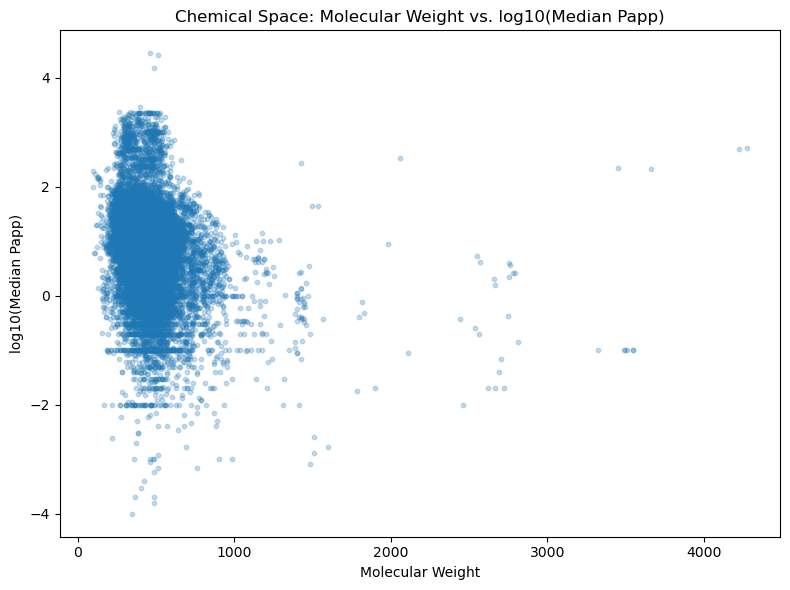

In [32]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    df_tda["MW"],
    df_tda["log10_median_papp"],
    alpha=0.25,
    s=10
)

plt.xlabel("Molecular Weight")
plt.ylabel("log10(Median Papp)")
plt.title("Chemical Space: Molecular Weight vs. log10(Median Papp)")

plt.tight_layout()
plt.show()

# chemical-space plot for LogP, because LogP is particularly relevant to permeability.

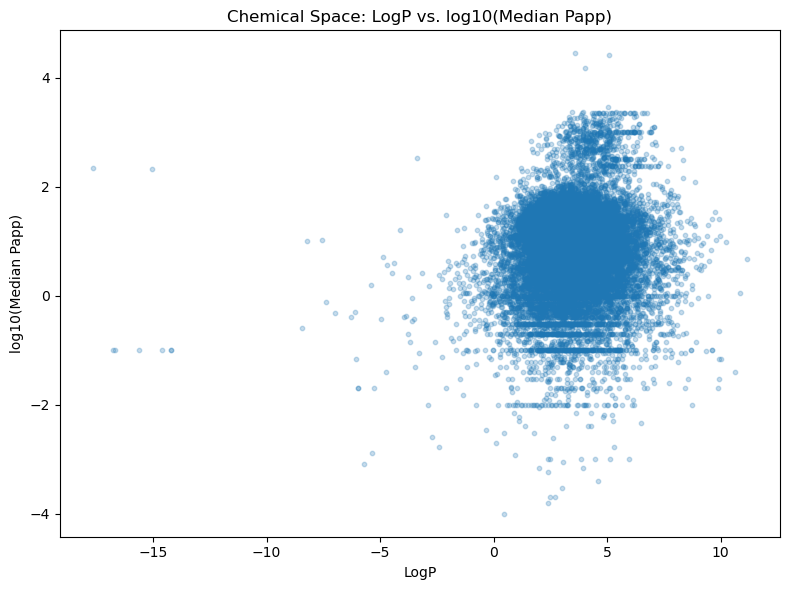

In [33]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df_tda["LogP"],
    df_tda["log10_median_papp"],
    alpha=0.25,
    s=10
)

plt.xlabel("LogP")
plt.ylabel("log10(Median Papp)")
plt.title("Chemical Space: LogP vs. log10(Median Papp)")

plt.tight_layout()
plt.show()

Chemical-space exploration based on molecular descriptors showed substantial dispersion of log10(median Papp) across the molecular-weight and lipophilicity ranges represented in the dataset. Although most compounds occupied a relatively concentrated region of chemical space, considerable variation in permeability was observed among compounds with similar molecular weight or LogP, indicating that these individual descriptors do not fully capture the determinants of Papp. Sparse regions containing compounds with extreme descriptor values were retained for subsequent assessment rather than excluded solely on the basis of their descriptor values.

# HBD

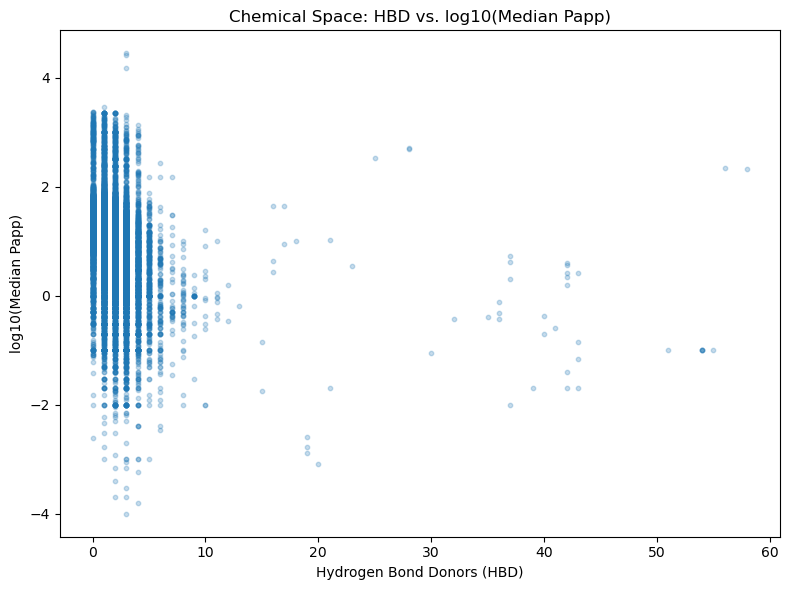

In [36]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df_tda["HBD"],
    df_tda["log10_median_papp"],
    alpha=0.25,
    s=10
)

plt.xlabel("Hydrogen Bond Donors (HBD)")
plt.ylabel("log10(Median Papp)")
plt.title("Chemical Space: HBD vs. log10(Median Papp)")

plt.tight_layout()
plt.show()

# HBA vs. log10(Median Papp)

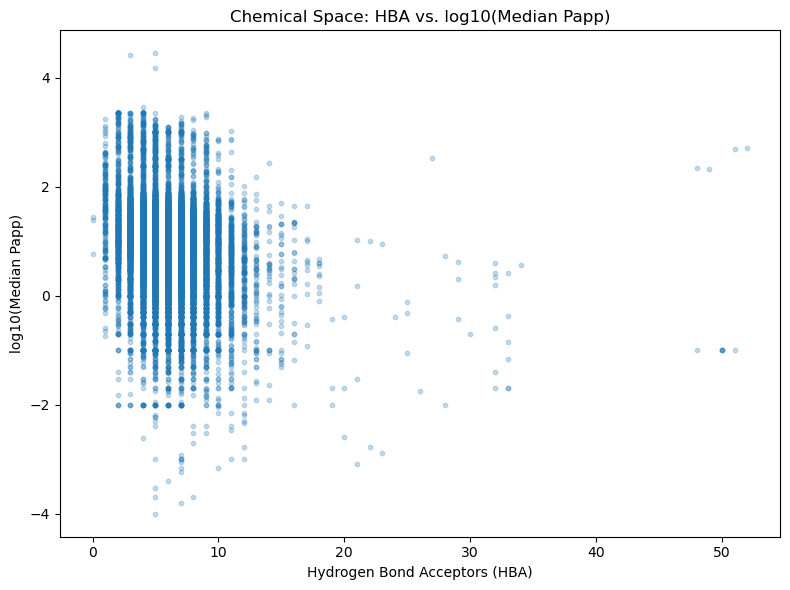

In [37]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df_tda["HBA"],
    df_tda["log10_median_papp"],
    alpha=0.25,
    s=10
)

plt.xlabel("Hydrogen Bond Acceptors (HBA)")
plt.ylabel("log10(Median Papp)")
plt.title("Chemical Space: HBA vs. log10(Median Papp)")

plt.tight_layout()
plt.show()

# TPSA vs. log10(Median Papp)

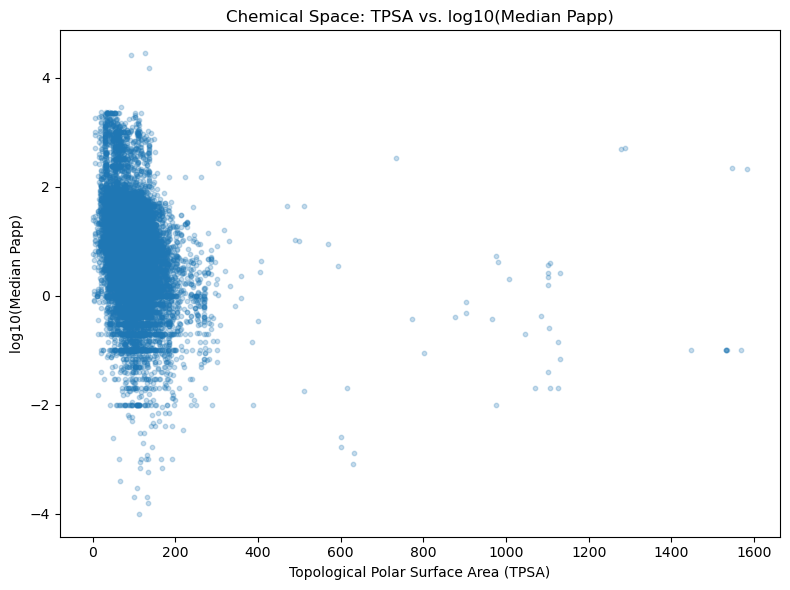

In [38]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df_tda["TPSA"],
    df_tda["log10_median_papp"],
    alpha=0.25,
    s=10
)

plt.xlabel("Topological Polar Surface Area (TPSA)")
plt.ylabel("log10(Median Papp)")
plt.title("Chemical Space: TPSA vs. log10(Median Papp)")

plt.tight_layout()
plt.show()

# Rotatable Bonds

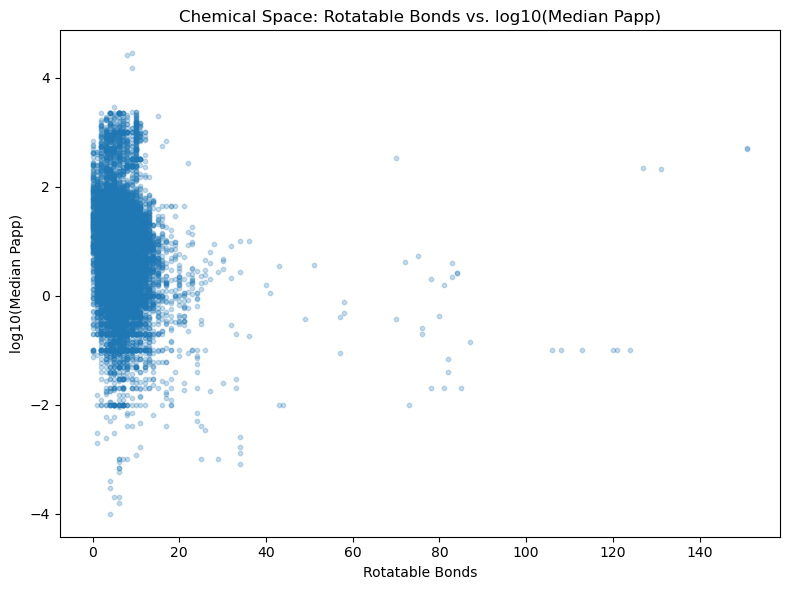

In [39]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df_tda["RotB"],
    df_tda["log10_median_papp"],
    alpha=0.25,
    s=10
)

plt.xlabel("Rotatable Bonds")
plt.ylabel("log10(Median Papp)")
plt.title("Chemical Space: Rotatable Bonds vs. log10(Median Papp)")

plt.tight_layout()
plt.show()

# Ring Count vs. log10(Median Papp)

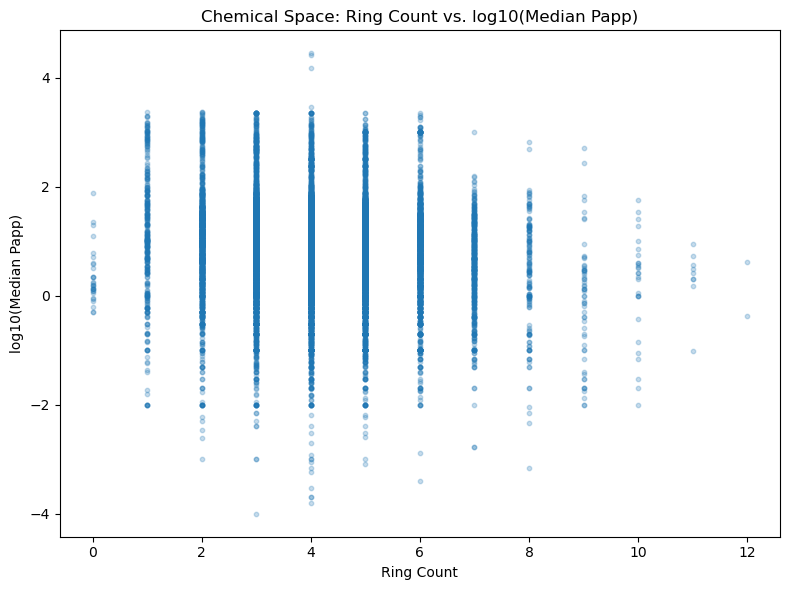

In [40]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df_tda["RingCount"],
    df_tda["log10_median_papp"],
    alpha=0.25,
    s=10
)

plt.xlabel("Ring Count")
plt.ylabel("log10(Median Papp)")
plt.title("Chemical Space: Ring Count vs. log10(Median Papp)")

plt.tight_layout()
plt.show()

In [41]:
# Descriptors for correlation analysis
descriptor_cols = [
    "MW",
    "LogP",
    "HBD",
    "HBA",
    "TPSA",
    "RotB",
    "RingCount"
]

target_col = "log10_median_papp"

# Pearson correlation
pearson_corr = df_tda[descriptor_cols + [target_col]].corr(
    method="pearson"
)[target_col].drop(target_col)

# Spearman correlation
spearman_corr = df_tda[descriptor_cols + [target_col]].corr(
    method="spearman"
)[target_col].drop(target_col)

# Combine results
correlation_df = pd.DataFrame({
    "Pearson_r": pearson_corr,
    "Spearman_rho": spearman_corr
})

print("Correlation with log10(Median Papp):")
print(correlation_df.sort_values("Spearman_rho"))

Correlation with log10(Median Papp):
           Pearson_r  Spearman_rho
TPSA       -0.259609     -0.330526
HBD        -0.228703     -0.314559
MW         -0.231520     -0.254411
HBA        -0.218573     -0.203209
RotB       -0.162086     -0.190911
RingCount  -0.123292     -0.113347
LogP        0.099375      0.057882


# Descriptor–descriptor correlation

In [43]:
descriptor_cols = [
    "MW",
    "LogP",
    "HBD",
    "HBA",
    "TPSA",
    "RotB",
    "RingCount"
]

descriptor_corr = df_tda[descriptor_cols].corr(method="spearman")

print(descriptor_corr.round(3))

              MW   LogP    HBD    HBA   TPSA   RotB  RingCount
MW         1.000  0.393  0.319  0.583  0.602  0.647      0.546
LogP       0.393  1.000 -0.082 -0.129 -0.186  0.282      0.334
HBD        0.319 -0.082  1.000  0.231  0.612  0.314     -0.006
HBA        0.583 -0.129  0.231  1.000  0.741  0.374      0.452
TPSA       0.602 -0.186  0.612  0.741  1.000  0.404      0.239
RotB       0.647  0.282  0.314  0.374  0.404  1.000      0.117
RingCount  0.546  0.334 -0.006  0.452  0.239  0.117      1.000


# visualize this correlation structure

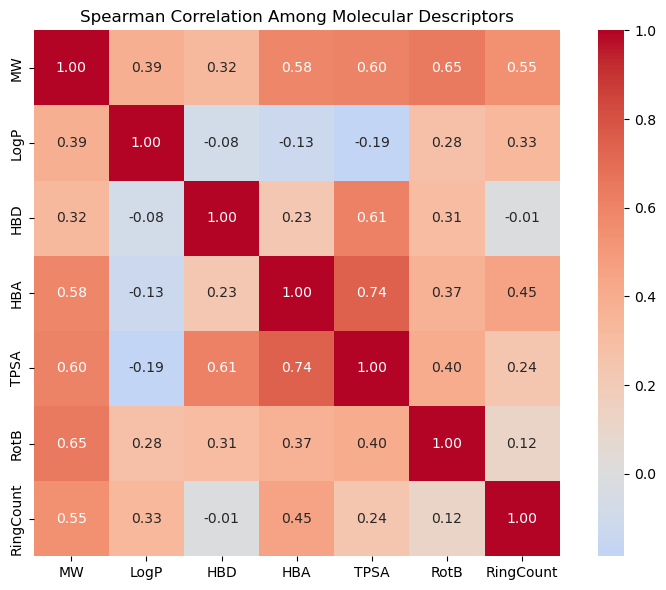

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))

sns.heatmap(
    descriptor_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title("Spearman Correlation Among Molecular Descriptors")
plt.tight_layout()
plt.show()

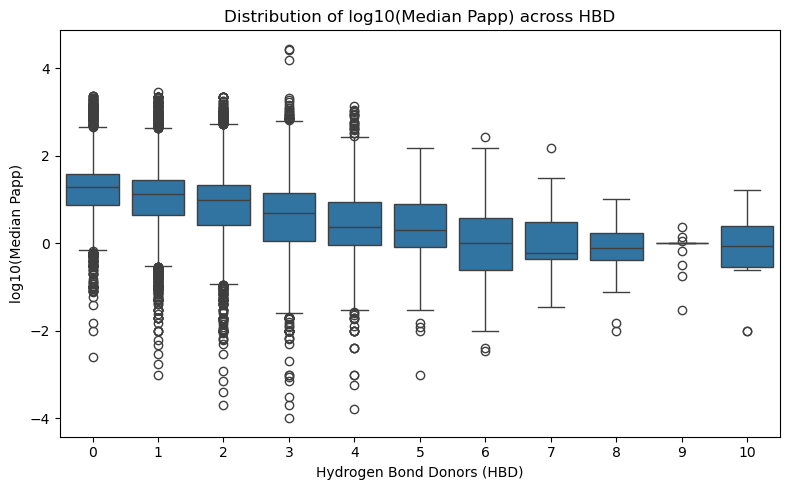

In [45]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_tda[df_tda["HBD"] <= 10],
    x="HBD",
    y="log10_median_papp"
)

plt.xlabel("Hydrogen Bond Donors (HBD)")
plt.ylabel("log10(Median Papp)")
plt.title("Distribution of log10(Median Papp) across HBD")
plt.tight_layout()
plt.show()

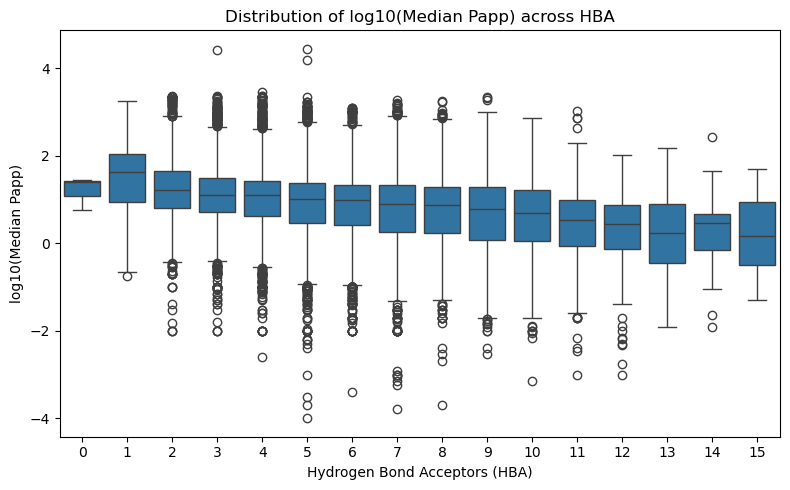

In [46]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_tda[df_tda["HBA"] <= 15],
    x="HBA",
    y="log10_median_papp"
)

plt.xlabel("Hydrogen Bond Acceptors (HBA)")
plt.ylabel("log10(Median Papp)")
plt.title("Distribution of log10(Median Papp) across HBA")

plt.tight_layout()
plt.show()